# 02 — Results and analysis

All numbers are on the **test** set. Hyperparameters, threshold strategy and thresholds were chosen on **dev** only. Each model is shown at its dev-selected threshold strategy. Logic lives in `src/analysis.py`; the master table comes from `src/compare.py`.

`regex_mention` is a *diagnostic*, not a model: it predicts §N whenever the text literally cites "section N". It measures how much of the task is solvable by reading citations left in the judgment.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd
import analysis as A
from common import load_statutes
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 120)
OUT = A.OUT
ctx = A.load_context()
base, bert = A.load_model(ctx, "best_baseline"), A.load_model(ctx, "best_bert")
regex = A.Model("regex_mention", "outputs/baselines/regex_mention", "global", ctx["label_list"])
statutes = load_statutes().set_index("section_id")["text"].to_dict()
print("best baseline (dev):", base.name, base.strategy, "| best BERT (dev):", bert.name, bert.strategy)

best baseline (dev): tfidf_lr per_label | best BERT (dev): inlegalbert_head_512 per_label


## 1. Master table and micro vs macro F1

,model,thresholds,test_micro_f1,test_macro_f1,test_micro_p,test_micro_r,test_samples_f1,dev_micro_f1
0,keyword,global,0.1756,0.1071,0.1623,0.1914,0.1308,0.1741
1,regex_mention,t0.5,0.7007,0.6271,0.7028,0.6985,0.6399,0.7053
2,tfidf_lr,per_label,0.6908,0.5854,0.7072,0.6751,0.6545,0.6995
3,bert-base-uncased_head_512,per_label,0.4970,0.4173,0.4293,0.5901,0.4819,0.5144
4,inlegalbert_head_512,per_label,0.5205,0.4447,0.4662,0.5891,0.5001,0.5365
5,inlegalbert_head_tail_512,per_label,0.5114,0.4357,0.4583,0.5784,0.4949,0.5271


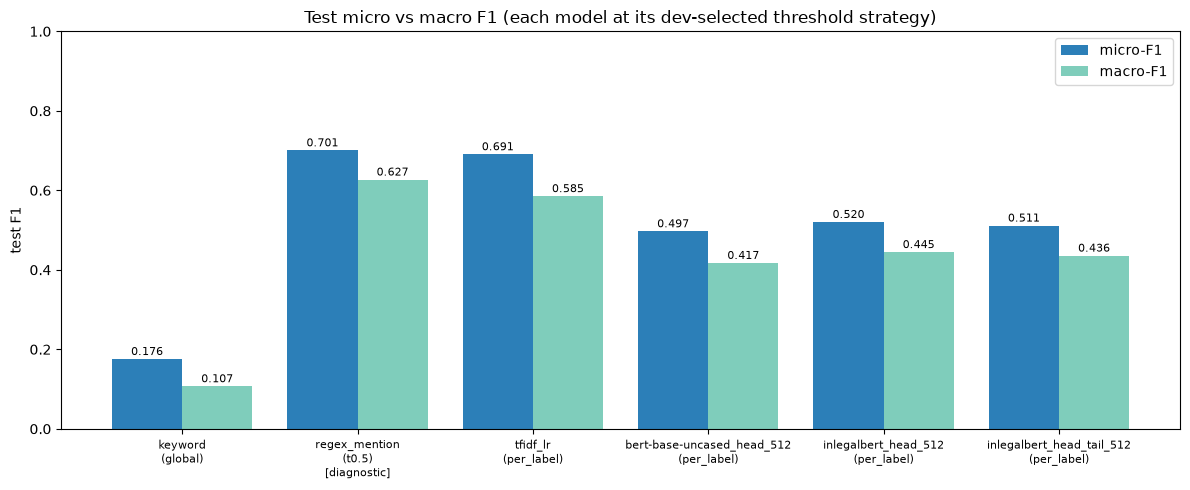

In [2]:
rows = A.plot_micro_macro(ctx["results"], OUT / "micro_macro_f1.png")
rows[["model", "thresholds", "test_micro_f1", "test_macro_f1", "test_micro_p", "test_micro_r",
      "test_samples_f1", "dev_micro_f1"]].round(4)

**Reading the table.** TF-IDF + logistic regression is the strongest real model (test micro-F1 **0.691**, macro-F1 **0.585**). The best BERT, InLegalBERT with head truncation, reaches 0.521 / 0.445. Legal-domain pretraining helps: InLegalBERT beats bert-base-uncased by +2.4 micro and +2.7 macro points. Keeping the end of the document (head_tail) did **not** help (−0.9 micro). The `regex_mention` diagnostic (0.701 / 0.627) is about as good as TF-IDF without learning anything: a large share of ILSI is solvable by reading section numbers that the judgments cite verbatim. Per-label thresholds were picked on dev for every learned model and give +1–2 micro-F1 over a single global threshold. The untuned 0.5 threshold is badly off for BERT (precision 0.26) because `pos_weight` pushes all probabilities up.

## 2. Per-label F1 vs label frequency

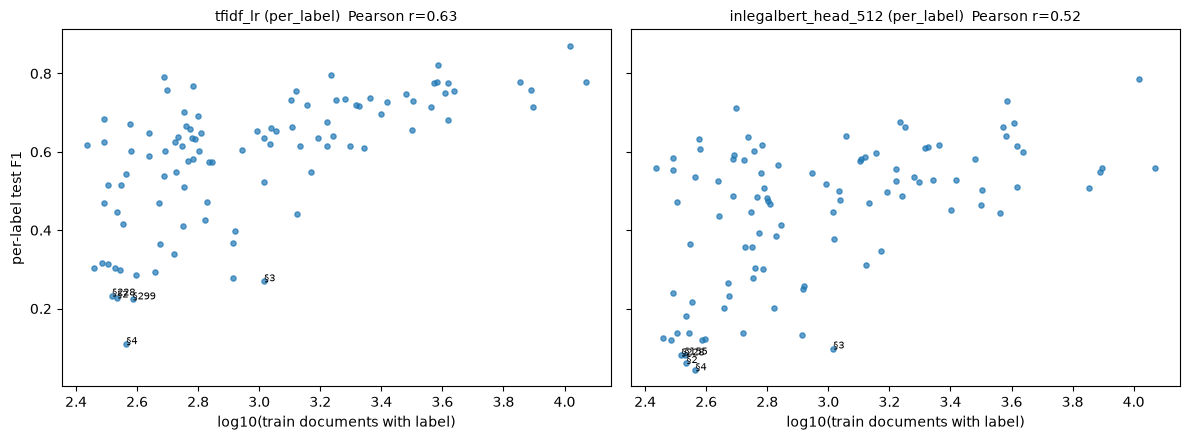

In [3]:
f1 = A.plot_f1_vs_freq(ctx, [base, bert], OUT / "f1_vs_frequency.png")
f1.to_csv(OUT / "per_label_f1_best_models.csv")

Both models do better on frequent sections (Pearson r between log train frequency and F1: 0.63 for TF-IDF, 0.52 for InLegalBERT), but frequency is not the whole story: several tail labels with ~300 training documents still reach F1 > 0.6 with TF-IDF. The hardest labels for both models are the **general/procedural sections §2, §3, §4** (and §228, §155). §2–§5 describe where the Code applies rather than an offence, so the facts carry little signal for them; their presence as labels is probably an artefact of how citations were extracted.

## 3. Head / mid / tail buckets

,head,mid,tail
model,,,
keyword,0.176,0.083,0.061
regex_mention,0.759,0.621,0.497
tfidf_lr,0.708,0.582,0.463
bert-base-uncased_head_512,0.546,0.409,0.293
inlegalbert_head_512,0.557,0.438,0.336
inlegalbert_head_tail_512,0.550,0.424,0.329


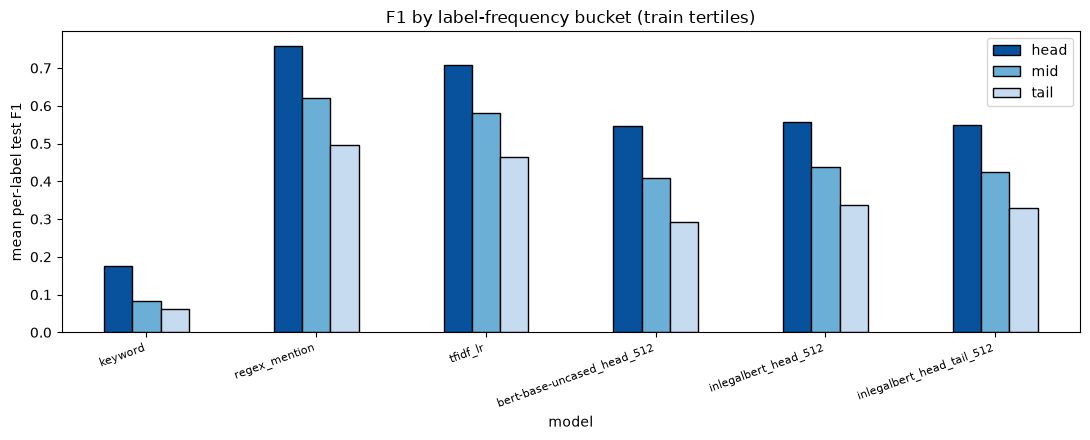

In [4]:
A.plot_buckets(ctx["results"], OUT / "bucket_f1.png").round(3)

The ranking is the same in every bucket (regex ≥ TF-IDF > InLegalBERT > BERT-base ≫ keyword), and the learned models lose 0.22–0.26 F1 from head to tail. BERT's gap to TF-IDF is roughly constant in absolute terms (−0.15 head, −0.14 mid, −0.13 tail), so BERT is not specifically better on rare labels; InLegalBERT's advantage over BERT-base is largest on the tail (+0.04).

## 4. Where BERT gains and loses against the best baseline (per-label F1)

In [5]:
gain, loss = A.improvement_table(f1, base.name, bert.name, statutes, ctx["train_counts"])
gain.to_csv(OUT / "bert_largest_gains.csv"); loss.to_csv(OUT / "bert_largest_losses.csv")
print("15 labels where BERT improves MOST over the baseline"); display(gain.round(3))
print("15 labels where BERT improves LEAST (most negative)"); display(loss.round(3))

15 labels where BERT improves MOST over the baseline


,train_docs,F1 tfidf_lr,F1 inlegalbert_head_512,delta (BERT - base),statute (first 70 chars)
337,380,0.602,0.608,0.007,Whoever causes hurt to any person by doing any act so rashly or neglig
308,544,0.637,0.637,-0.000,Whoever does any act with such intention or knowledge and under such c
186,684,0.574,0.568,-0.006,Whoever voluntarily obstructs any public servant in the discharge of h
457,365,0.543,0.536,-0.007,"Whoever commits lurking house-trespass by night, or house-breaking by"
509,491,0.602,0.591,-0.012,"Whoever, intending to insult the modesty of any woman, utters any word"
294(b),1139,0.653,0.640,-0.013,"(b) sings, recites or utters any obscene song, ballad or words, in or"
500,377,0.670,0.633,-0.037,Whoever defames another shall be punished with simple imprisonment for
338,319,0.515,0.472,-0.044,Whoever causes grievous hurt to any person by doing any act so rashly
188,528,0.624,0.579,-0.045,"Whoever, knowing that, by an order promulgated by a public servant law"
279,498,0.758,0.712,-0.046,"Whoever drives any vehicle, or rides, on any public way in a manner so"


15 labels where BERT improves LEAST (most negative)


,train_docs,F1 tfidf_lr,F1 inlegalbert_head_512,delta (BERT - base),statute (first 70 chars)
437,577,0.665,0.305,-0.360,Whoever commits mischief to any decked vessel or any vessel of a burde
465,609,0.582,0.301,-0.281,Whoever commits forgery shall be punished with imprisonment of either
324,3662,0.715,0.444,-0.271,"Whoever, except in the case provided for by section 334, voluntarily c"
307,7124,0.779,0.509,-0.270,"Whoever does any act with such intention or knowledge, and under such"
411,592,0.659,0.393,-0.266,"Whoever dishonestly receives or retains any stolen property, knowing o"
13,341,0.445,0.182,-0.264,Rep. by the A.O. 1950.
326,2513,0.695,0.452,-0.243,"Whoever, except in the case provided for by section 335, voluntarily c"
320,566,0.510,0.277,-0.232,"The following kinds of hurt only are designated as ""grievous"" (First)"
366A,310,0.468,0.240,-0.228,"Whoever, by any means whatsoever, induces any minor girl under the age"
341,3186,0.731,0.503,-0.227,Whoever wrongfully restrains any person shall be punished with simple


BERT does not beat TF-IDF on any label by a meaningful margin: its best case is §337 (+0.007), and it is ≥ TF-IDF on only 1 of 100 labels. The largest losses are on sections where the exact number is the main evidence and siblings look alike in prose: §437 vs §436 (mischief to vessels vs by fire), §465 (forgery), the hurt family §323/§324/§326, §307 and §34. These are labels that TF-IDF can pick up from a cited "section 324" n-gram, while BERT has to infer them from a description of the injury, which is genuinely ambiguous between neighbouring hurt sections.

## 5. Most-confused section pairs

`count` = test docs where `pred_FP` is predicted but **not** gold while `gold` **is** gold; `rate` = count / docs with `gold`. These are false positives that ride along with a related true label.

In [6]:
conf = {m.name: A.confusion_pairs(ctx["y_test"], m.pred, ctx["label_list"]) for m in [base, bert]}
for name, c in conf.items():
    c.to_csv(OUT / f"confusions_{name}.csv", index=False)
    print(f"Top 12 confusions: {name}"); display(c.head(12).round(3))

Top 12 confusions: tfidf_lr


,pred_FP,gold,count,rate_given_gold
0,34,302,304,0.094
1,304,302,234,0.072
2,300,302,227,0.070
3,313,302,223,0.069
4,506,294,201,0.222
5,506,323,169,0.068
6,299,302,167,0.051
7,34,307,166,0.075
8,34,323,160,0.064
9,34,149,154,0.129


Top 12 confusions: inlegalbert_head_512


,pred_FP,gold,count,rate_given_gold
0,34,302,940,0.290
1,307,34,905,0.242
2,307,302,874,0.269
3,307,323,874,0.351
4,304,302,688,0.212
5,34,307,645,0.290
6,323,34,638,0.171
7,34,323,635,0.255
8,323,307,611,0.275
9,506,323,594,0.238


In [7]:
focus = A.focus_confusions(conf, ctx["label_list"])
focus.to_csv(OUT / "focus_confusions.csv", index=False)
focus

,pred_FP,gold,tfidf_lr count,tfidf_lr rate,inlegalbert_head_512 count,inlegalbert_head_512 rate
0,302,304,78,0.079,134,0.136
1,304,302,234,0.072,688,0.212
2,323,324,75,0.065,309,0.270
3,323,325,76,0.087,283,0.325
4,324,323,53,0.021,368,0.148
5,324,325,23,0.026,189,0.217
6,325,323,73,0.029,202,0.081
7,325,324,24,0.021,110,0.096
8,420,406,29,0.040,55,0.076
9,406,420,39,0.031,153,0.121


TF-IDF's false positives are few and spread out; its top confusions are co-charged sections that ride along with murder (§34, §304, §300, §313 with gold §302). **InLegalBERT confuses the same families but 3–4× more often**: it over-predicts §34 (common intention) whenever §302/§307/§149 is gold (34|149 at 41% vs 13% for TF-IDF), mixes the murder ladder §302/§304/§307, and the hurt ladder §323/§324/§325 (e.g. predicting §324 in 15% of §323 docs vs 2% for TF-IDF). Rioting §147/§148/§149 and cheating/criminal breach of trust §420/§406 are confused less often overall (BERT 8–17%, TF-IDF 3–11%), though BERT predicts §406 in 12% of §420 documents vs 3% for TF-IDF. These are legally adjacent sections that are often charged together, and distinguishing them requires details (weapon type, injury severity, intention) that a 510-token head of the judgment often does not contain.

## 6. Where are the answers? Citation position vs truncation

For each test document: the word position at which a gold section is first cited as "section N". BERT sees roughly the first ~400 words.

In [8]:
stats, pos = A.mention_position_stats(ctx)
print(stats)
by_group = A.f1_by_mention_group(ctx, [base, bert, regex], pos)
by_group.to_csv(OUT / "f1_by_citation_position.csv", index=False)
by_group

{'docs': 13039, 'a gold section is named somewhere': 0.811, 'first named within first ~400 words': 0.654, 'first named only after ~400 words': 0.158}


,group,docs,tfidf_lr,inlegalbert_head_512,regex_mention
0,named in first ~400 words,8521,0.7630,0.5897,0.7830
1,named only after ~400 words,2060,0.6883,0.4310,0.7595
2,never named,2458,0.3516,0.3099,0.0680


**This is the key diagnostic.** A citation parser (lists such as "Sections 147, 148 and 149" and "302 I.P.C" included) finds a gold section cited within the first ~400 words in 65.4% of test documents, only later in 15.8%, and never in 18.9%. (1) When the citation is early, TF-IDF and regex reach 0.76–0.78 micro-F1 but BERT only 0.59, so BERT does not reliably *read* cited numbers even when they are inside its window. (2) When the citation is late, BERT drops to 0.43 (truncation) while TF-IDF holds at 0.69 (it sees the whole document). (3) When no gold section is cited, every model is weak; this is the setting closest to the real task of *predicting* statutes from facts. TF-IDF still leads narrowly (0.35 vs 0.31), the regex collapses to 0.07, so both learned models are genuinely inferring offences from facts there.

## 7. Error analysis

Documents where one model gets doc-level F1 ≥ 0.75 and the other ≤ 0.25 (8 sampled with seed 42 from all qualifying docs). Facts are truncated to 500 characters.

In [9]:
bert_fail, n1 = A.error_cases(ctx, base, bert)
base_fail, n2 = A.error_cases(ctx, bert, base)
bert_fail.to_csv(OUT / "errors_bert_failed.csv", index=False); base_fail.to_csv(OUT / "errors_baseline_failed.csv", index=False)
print(f"{n1} docs where BERT failed and {base.name} succeeded; {n2} docs where the reverse happened")

370 docs where BERT failed and tfidf_lr succeeded; 32 docs where the reverse happened


### 7a. BERT failed, baseline succeeded

In [10]:
for _, r in bert_fail.iterrows():
    print(f"--- row {r['row']} (id {r['id']}, {r['words']} words) | gold {r['gold']}")
    print(f"    {base.name}: {r['pred ' + base.name]}  (docF1 {r['docF1 ' + base.name]})")
    print(f"    {bert.name}: {r['pred ' + bert.name]}  (docF1 {r['docF1 ' + bert.name]})")
    print(f"    gold named in text: {r['gold named in text']} | first gold mention at word {r['first gold mention at word']}")
    print("    " + r["facts (first 500 chars)"].replace("\n", " ")[:500] + "\n")

--- row 1192 (id 176936089, 92 words) | gold ['294', '325']
    tfidf_lr: ['294', '325', '506']  (docF1 0.8)
    inlegalbert_head_512: ['34', '307', '323', '324', '325', '326', '506']  (docF1 0.22)
    gold named in text: ['294', '325'] | first gold mention at word 2
    M under Sections 294, 325, 506-II of the IPC. It is submitted by the counsel for the State that the trial Court of has committed a material illegality by disbelieving the evidence of rt complainant Meharban Singh (P.W-1). Even if there was certain ou improvements in the evidence of the other witnesses then that cannot be a ground to discard the reliable evidence of Meharban Singh C (P.W-1). Therefore, the judgment passed by the trial Court suffers h from perversity. The office is directed to reg

--- row 1195 (id 1277706, 4262 words) | gold ['148', '149', '302', '365']
    tfidf_lr: ['148', '149', '302']  (docF1 0.86)
    inlegalbert_head_512: ['34', '120B', '201', '302', '364']  (docF1 0.22)
    gold named in text: ['

**Comments (row: what happened).** 370 docs qualify, 8 shown.
* **1192**: "Sections 294, 325, 506-II" is in the first sentence, yet BERT predicts a generic hurt/assault cluster (34, 307, 323–326). BERT does not copy explicit citations. Note §506 is cited but not in the gold set: gold labels are themselves noisy.
* **1195**: 4,262 words; all gold sections are first cited at word 1,496, beyond BERT's window. From the narrative (armed men, abduction) BERT guesses §364 (kidnapping to murder) instead of §365, and §120B/§201. *Truncation.*
* **5582**: a 12,118-word judgment with 21 gold sections. The only citations inside BERT's window (from word 57) belong to a procedural preamble: "328, 379 and 411 I.P.C.". BERT predicts exactly 379 and 411, both gold; the other 19 gold sections are cited only later. *Truncation plus a misleading preamble.*
* **5727**: gold cited only at word 2,107. From the facts (missing girl, body found, post-mortem) BERT predicts §376 and §201, which is plausible from the narrative, but misses §302/§363. *Truncation.*
* **8873**: opens as a service-law writ petition about a college lecturer; criminal sections appear only at word 1,540. BERT has no criminal facts to work with. *Truncation.*
* **9682**: a 286-word bail order citing "Sections 363, 366, 376, 506, IPC" at word 39. BERT predicts only §229A (failure to appear when on bail): it keyed on the document *genre* (bail application), not on the offence. Clear failure to use an in-window citation.
* **10701**: an attempt-to-murder case (307/324/326, cited at word 291). BERT predicts the homicide ladder (299, 300, 302, 304, 307): right family, wrong severity.
* **11516**: robbery (§392) cited at word 1,490; BERT predicts §397 (robbery with a deadly weapon), a sibling section. *Truncation plus a near-miss.*

Pattern: 5/8 are long documents whose (relevant) citations lie beyond the 510-token window; 3/8 show BERT ignoring citations that it could see and predicting a semantically related cluster instead.

### 7b. Baseline failed, BERT succeeded

In [11]:
for _, r in base_fail.iterrows():
    print(f"--- row {r['row']} (id {r['id']}, {r['words']} words) | gold {r['gold']}")
    print(f"    {bert.name}: {r['pred ' + bert.name]}  (docF1 {r['docF1 ' + bert.name]})")
    print(f"    {base.name}: {r['pred ' + base.name]}  (docF1 {r['docF1 ' + base.name]})")
    print(f"    gold named in text: {r['gold named in text']} | first gold mention at word {r['first gold mention at word']}")
    print("    " + r["facts (first 500 chars)"].replace("\n", " ")[:500] + "\n")

--- row 1211 (id 108835355, 136 words) | gold ['302']
    inlegalbert_head_512: ['302']  (docF1 1.0)
    tfidf_lr: ['149']  (docF1 0.0)
    gold named in text: [] | first gold mention at word nan
    P. C. : Said Ganesh (accused no.1) died during the pendency of trial. They were sentenced to suffer imprisonment for life. That apart, during the trial period, applicants wereon bail. In above circumstances, we are inclined to grant bailto the Applicants. We, therefore, dispose of this application bypassing following order : (e) The Applicants shall keep vakalatnama of his advocate alive and valid till the appeal is finally decided by this Court and they shall not be entitled to any fresh notice

--- row 5207 (id 49234731, 389 words) | gold ['13', '174A', '201', '229A', '409', '420', '467', '468', '471']
    inlegalbert_head_512: ['13', '120B', '409', '420', '467', '468', '471']  (docF1 0.75)
    tfidf_lr: ['120B', '420']  (docF1 0.18)
    gold named in text: [] | first gold mention at wor

**Comments.** Only 32 docs qualify in this direction (vs 370 above). All 8 shown are **short (131–432 words)**, and in 7 of 8 no gold section is cited in the text.
* **1211**: no citation; "sentenced to suffer imprisonment for life" and a co-accused who died. BERT infers §302; TF-IDF guesses §149.
* **5207**: a CBI case about a Rs 45-lakh fraud. BERT recovers most of the forgery/cheating/breach-of-trust cluster (409, 420, 467, 468, 471); TF-IDF only 120B/420. The gold set contains §13, an IPC section repealed in 1950; this looks like label noise, *possibly* a citation of Section 13 of another Act (e.g. the Prevention of Corruption Act) linked to the IPC (unverified hypothesis).
* **8258**: a neighbours' quarrel with injuries, later settled. BERT predicts the typical hurt/intimidation cluster (34, 323, 506); TF-IDF keys on the word "proposed" … "married" and predicts §509 (insulting a woman's modesty).
* **9460**: "Section 376" is cited at word 31, but TF-IDF predicts §3. The short text is dominated by court-website boilerplate ("Uploaded on … Downloaded on …"); TF-IDF's *probable* failure mode is that these boilerplate n-grams carry more weight than the single citation (hypothesis).
* **9767**: a fatal quarrel over a well; the section numbers were stripped from the text ("… I.P.C. as against the appellant"). BERT gets the homicide ladder (300, 302, 304); TF-IDF only §34.
* **11179**: "prosecuted originally with. We are not …": the citation appears to have been *removed* from this sentence, so ILSI does mask some citations. BERT infers the rioting trio §147/148/149 from "five appellants"; TF-IDF predicts §326.
* **11655**: a bail application about a fraudulent land sale. Gold is procedural (§174A non-appearance after proclamation, §229A bail-jumping), which BERT gets exactly; TF-IDF predicts the cheating/forgery cluster from the land-fraud facts.
* **12599**: a PIL about unexplained wealth. BERT predicts 120B/409/420 correctly; TF-IDF predicts §13.

Pattern: BERT wins when the document is short and the offence must be inferred from the narrative; TF-IDF wins when a citation exists anywhere in a long document.

## 8. Significance: paired bootstrap (1000 resamples of test documents, seed 42)

In [12]:
bs = A.paired_bootstrap(ctx["y_test"], base.pred, bert.pred, n_boot=1000, seed=42)
(OUT / "bootstrap.json").write_text(json.dumps({"a": base.name, "b": bert.name, **bs}, indent=1))
pd.DataFrame({k: {f"{base.name} (a)": f"{v['a']:.4f} {v['a_CI95']}", f"{bert.name} (b)": f"{v['b']:.4f} {v['b_CI95']}",
                  "b - a [95% CI]": f"{v['diff_b_minus_a']:+.4f} {v['diff_CI95']}", "p (two-sided)": v["p_two_sided"]}
              for k, v in bs.items()})

,micro_f1,macro_f1
tfidf_lr (a),"0.6908 [0.6857, 0.696]","0.5854 [0.5779, 0.5917]"
inlegalbert_head_512 (b),"0.5205 [0.5155, 0.5249]","0.4447 [0.4379, 0.4502]"
b - a [95% CI],"-0.1703 [-0.1747, -0.1659]","-0.1407 [-0.1469, -0.134]"
p (two-sided),< 0.001,< 0.001


The difference is large and highly significant: TF-IDF LR beats InLegalBERT by **17.0 micro-F1 points (95% CI 16.6–17.5)** and **14.1 macro-F1 points (95% CI 13.4–14.7)**. No resample out of 1,000 favoured BERT (p < 0.001). The 95% intervals of the two models do not overlap for either metric. Caveat: the bootstrap resamples test *documents* and treats thresholds as fixed; it does not capture variance from training seeds (each BERT configuration was trained once, seed 42).

## 9. Takeaways

1. **On ILSI as released, a bag-of-words model beats fine-tuned BERT** (0.691 vs 0.521 micro-F1, p < 0.001), and a citation regex alone matches TF-IDF. Most of ILSI's signal is section numbers written into the judgments, which whole-document lexical models exploit and 512-token BERT only partly sees.
2. **The gap comes from two things:** (a) truncation: 15.8% of documents cite gold sections only after BERT's window, and on them BERT falls to 0.43; (b) BERT does not reliably use in-window citations (0.59 vs 0.78 for regex).
3. **On the realistic subset with no citation in the text** (18.9% of test), all models are weak (0.31–0.35) and both beat the regex diagnostic (0.07), so it is learning facts→offence associations. A fairer benchmark would mask section numbers; that is the obvious next experiment.
4. InLegalBERT > bert-base-uncased (+2.4 micro, +2.7 macro); head+tail truncation did not help.
5. Errors are dominated by legally adjacent, co-charged sections (302/304/307, 323/324/325, 147/148/149, 34 with everything), and gold labels themselves contain noise (cited sections missing from gold; repealed §13 and the non-offence sections §2–5 as labels).